Demographic Parity Difference: 0.07480130902290782
Disparate Impact Ratio: 1.1153652029706538
Consistency: 0.669000000000001


/Users/leonardobrogi/Desktop/ads/courses/datawrangling/ass4/model/utils/dataloader.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target.replace(['M', 'F'], [1, 0], inplace=True)


Y TEST:      classification  gender
405               0       1
926               1       0
593               0       0
819               0       1
714               0       1
..              ...     ...
998               0       1
873               1       0
335               0       1
751               0       0
555               0       1

[100 rows x 2 columns]
Demographic Parity Difference: 0.07947639083683966
Disparate Impact Ratio: 1.1231884057971016
Consistency: 0.6200000000000001
>>>>>>>>fit_called<<<<<<<<<<
250 83.36627812671965
500 83.36628079410349
750 72.10468698458742
1000 72.10468260790135
1250 72.10468683038026
1500 70.55617769973165
1750 70.55617742538482
2000 68.97997193466038
2250 68.97997088453717
2500 68.9799714315092
2750 67.6827841262905
3000 67.68272763374456
3250 67.68273381745047
3500 68.10581643673056
3750 68.10581655657035
4000 67.42105357344708
4250 67.42105425973449
4500 67.42105490282165
4750 67.04159901869532
5000 67.0415918890091
5250 67.04159549179093


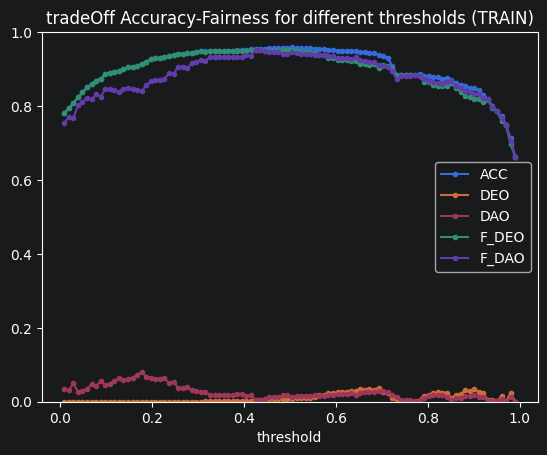

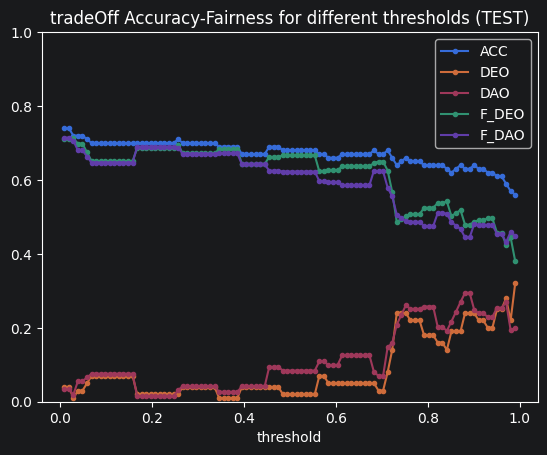

Next the metrics used by zemel, et al.
Accuracy: 0.6720892332938961
Discrimination: 0.013048798656664529
Consistency: 0.42447815897034935


In [1]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from model.utils.metrics import *
from model.utils.dataloader import dataloader
from model.LFR import LFR
import matplotlib.pyplot as plt
import numpy as np
import random
import csv

random.seed(42)
np.random.seed(42)


if __name__=='__main__':
    sensitive_feature = 'gender'
    DF = 'german' #or 'adult'

    with open("Fairness_Measures.csv", 'w', newline='') as file:
        writer = csv.writer(file)
    # calculating the DP-Diff, DI-Ratio and Consistency of the whole data,
    # before the mitigation
    if DF == 'german':
        from calc_German import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=1, x_test=None, y_test=None, y_pred=None)
    elif DF == 'adult':
        from calc_adult import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=1, x_test=None, y_test=None, y_pred=None)

    with open("Fairness_Measures.csv", 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Process", "Parity Difference", "Disparate Impact Ratio", "Consistency", "Accuracy"])
        writer.writerow(["Whole data before mitigation", DP_Diff, DIR, final_consistency, "-"])
    data = dataloader(DF, sensitive_feature =sensitive_feature) # else adult
    dataset, target, numvars, categorical = data
    # Split data into train and test
    x_train, x_test, y_train, y_test = train_test_split(dataset,
                                                        target,
                                                        test_size=0.1,
                                                        random_state=42,
                                                        stratify=target)


    classification = target.columns.to_list()
    classification.remove(sensitive_feature)
    classification = classification[0]
    # We create the preprocessing pipelines for both numeric and categorical data.
    numeric_transformer = Pipeline(
        steps=[('scaler', StandardScaler())])

    categorical_transformer = Pipeline(
        steps=[('onehot', OneHotEncoder(handle_unknown='ignore',sparse=False))])

    transformations = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numvars),
            ('cat', categorical_transformer, categorical)])

    pipeline = Pipeline(steps=[('preprocessor', transformations)])
    dict_all_result_in_grid = {}
    x_train = pipeline.fit_transform(x_train)
    x_test = pipeline.transform(x_test)
    parameters = {'k': 10, 'Ax': 0.001, 'Ay': 0.1, 'Az': 10.0, 'max_iter': 150000, 'max_fun': 150000}
    # calculate the parity difference (DP_Diff),
    # the disparate impact ratio (DIR), the consistency and
    # ... on the held-out test data (y_test) BEFORE mitigation
    print("Y TEST:", y_test)
    if DF == 'german':
        from calc_German import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=2, x_test=x_test, y_test=y_test, y_pred=None)
    elif DF == 'adult':
        from calc_adult import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=2, x_test=x_test, y_test=y_test, y_pred=None)

    with open("Fairness_Measures.csv", 'a', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Test data before mitigation", DP_Diff, DIR, final_consistency, "-"])

    lfr = LFR(sensitive_feature=sensitive_feature, privileged_class=1, unprivileged_class=0, seed=42,
              output_feature=classification, parameter=parameters)
    lfr.fit(X=x_train, y=y_train)
    Z_train, y_trainLFR = lfr.transform(X=x_train, y=y_train)


    bal_acc_arr_transf = []
    deo_arr_transf = []
    dao_arr_transf = []
    FairDEO = []
    FairDAO = []
    thresholds = np.linspace(0.01, 0.99, 100)
    svc = SVC(kernel='linear')
    svc.fit(Z_train, y_train[classification])

#    x_test = pipeline.transform(x_test)
    Z_test, y_testLFR = lfr.transform(X=x_test, y=y_test)
    print("X TEST:", x_test)

    y_pred = svc.predict(Z_test)
    print("Y PREDICTION:", y_pred)

    # calculate the parity difference (DP_Diff),
    # the disparate impact ratio (DIR), the consistency and
    # ... on the held-out test data (y_test) AFTER mitigation
    if DF == 'german':
        from calc_German import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=3, x_test=x_test, y_test=y_test, y_pred=y_pred)
    elif DF == 'adult':
        from calc_adult import calculate_3_fairness_measures
        DP_Diff, DIR, final_consistency = calculate_3_fairness_measures(process=3, x_test=x_test, y_test=y_test, y_pred=y_pred)

    ACC = accuracy_score(y_pred, y_test[classification])
    # adding Accuracy to the final csv file as the
    # predictive-performance measure.
    with open("Fairness_Measures.csv", 'a', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Test data after mitigation", DP_Diff, DIR, final_consistency, ACC])


    for thresh in thresholds:
        Y_pred = y_trainLFR.copy()
        Y_pred[classification] = np.array(Y_pred[classification] > thresh).astype(np.float64)
        ACC = accuracy_score(y_train[classification], Y_pred[classification])
        DEO = DifferenceEqualOpportunity(Y_pred[classification], y_train, sensitive_feature, classification, 1, 0, [0, 1])
        DAO = DifferenceAverageOdds(Y_pred[classification], y_train, sensitive_feature, classification, 1, 0, [0, 1])
        bal_acc_arr_transf.append(ACC)
        deo_arr_transf.append(DEO)
        dao_arr_transf.append(DAO)
        FairDEO.append(ACC * (1 - DEO))
        FairDAO.append(ACC * (1 - DAO))

    plt.title("tradeOff Accuracy-Fairness for different thresholds (TRAIN)")
    plt.plot(thresholds, bal_acc_arr_transf, marker='.')
    plt.plot(thresholds, deo_arr_transf, marker='.')
    plt.plot(thresholds, dao_arr_transf, marker='.')
    plt.plot(thresholds, FairDEO, marker='.')
    plt.plot(thresholds, FairDAO, marker='.')
    plt.ylim(0, 1)
    plt.legend(["ACC", "DEO", "DAO", "F_DEO", "F_DAO"])
    plt.xlabel("threshold")
    plt.show()
    bal_acc_arr_transf = []
    deo_arr_transf = []
    dao_arr_transf = []
    FairDEO = []
    FairDAO = []

    for thresh in thresholds:
        Y_pred = y_testLFR.copy()
        Y_pred[classification] = np.array(Y_pred[classification] > thresh).astype(np.float64)
        ACC = accuracy_score(y_test[classification], Y_pred[classification])
        DEO = DifferenceEqualOpportunity(Y_pred[classification], y_test, sensitive_feature, classification, 1, 0, [0, 1])
        DAO = DifferenceAverageOdds(Y_pred[classification], y_test, sensitive_feature, classification, 1, 0, [0, 1])
        bal_acc_arr_transf.append(ACC)
        deo_arr_transf.append(DEO)
        dao_arr_transf.append(DAO)
        FairDEO.append(ACC * (1 - DEO))
        FairDAO.append(ACC * (1 - DAO))

    plt.title("tradeOff Accuracy-Fairness for different thresholds (TEST)")
    plt.plot(thresholds, bal_acc_arr_transf, marker='.')
    plt.plot(thresholds, deo_arr_transf, marker='.')
    plt.plot(thresholds, dao_arr_transf, marker='.')
    plt.plot(thresholds, FairDEO, marker='.')
    plt.plot(thresholds, FairDAO, marker='.')
    plt.ylim(0, 1)
    plt.legend(["ACC", "DEO", "DAO", "F_DEO", "F_DAO"])
    plt.xlabel("threshold")
    plt.show()
    print("Next the metrics used by zemel, et al.")
    print("Accuracy: {}".format(accuracy(y_test[classification], y_testLFR[classification])))
    print("Discrimination: {}".format(discrimination(
        y_test, y_testLFR[classification], sensitive_feature,1,0)))
    print("Consistency: {}".format(consistency(x_test, y_testLFR[classification], k=5)))
